# Avocado Price Analysis Using Python
**Course:** PSC (CE0525) | **University:** Indus University | **Enrollment No.:** IU2441230585 | **Class:** 5 CSE-F

**Dataset:** [Avocado Prices (Kaggle)](https://www.kaggle.com/datasets/neuromusic/avocado-prices)
**GitHub:** https://github.com/ShresthBharucha/Avocado-Price-Analysis

**Workflow:** 1) Load data → 2) Data cleaning → 3) Exploratory Data Analysis → 4) Visualizations → 5) Insights report

## 1. Import Libraries

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

## 2. Load the Dataset
Download `avocado.csv` from the Kaggle link above and place it in the same folder as this notebook.
In **Google Colab**, run the cell below and upload the file when asked.

In [28]:
import os

# Looks for the dataset in the project's data/ folder, or next to the notebook
candidates = ["../data/avocado.csv", "data/avocado.csv", "avocado.csv"]
FILE = next((f for f in candidates if os.path.exists(f)), None)

if FILE is None:
    try:
        from google.colab import files   # works only inside Google Colab
        print("Please upload avocado.csv")
        files.upload()
        FILE = "avocado.csv"
    except ImportError:
        raise FileNotFoundError("avocado.csv not found. Download it from Kaggle and put it in the data/ folder.")

df = pd.read_csv(FILE)
print("Loaded:", FILE, "| Shape:", df.shape)
df.head()

Loaded: avocado.csv | Shape: (18249, 14)


,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


## 3. Understanding the Data

In [29]:
print("Columns:", list(df.columns))
print()
df.info()

Columns: ['Unnamed: 0', 'Date', 'AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 'XLarge Bags', 'type', 'year', 'region']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), int64(2), o

In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,18249.0,24.232232,1.548104e+01,0.00,10.00,24.00,38.00,52.00
AveragePrice,18249.0,1.405978,4.026766e-01,0.44,1.10,1.37,1.66,3.25
Total Volume,18249.0,850644.013009,3.453545e+06,84.56,10838.58,107376.76,432962.29,62505646.52
4046,18249.0,293008.424531,1.264989e+06,0.00,854.07,8645.30,111020.20,22743616.17
4225,18249.0,295154.568356,1.204120e+06,0.00,3008.78,29061.02,150206.86,20470572.61
4770,18249.0,22839.735993,1.074641e+05,0.00,0.00,184.99,6243.42,2546439.11
Total Bags,18249.0,239639.202060,9.862424e+05,0.00,5088.64,39743.83,110783.37,19373134.37
Small Bags,18249.0,182194.686696,7.461785e+05,0.00,2849.42,26362.82,83337.67,13384586.80
Large Bags,18249.0,54338.088145,2.439660e+05,0.00,127.47,2647.71,22029.25,5719096.61
XLarge Bags,18249.0,3106.426507,1.769289e+04,0.00,0.00,0.00,132.50,551693.65


## 4. Data Cleaning
Steps: (a) drop the useless index column, (b) rename columns, (c) fix data types, (d) check missing values,
(e) remove duplicates, (f) detect outliers.

### 4.1 Drop unnecessary column and rename columns

In [31]:
# The Kaggle file has an index column called 'Unnamed: 0' which carries no information
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")], errors="ignore")

# Clean, easy-to-use column names (4046/4225/4770 are PLU codes for avocado sizes)
df = df.rename(columns={
    "AveragePrice": "average_price",
    "Total Volume": "total_volume",
    "4046": "plu_4046",
    "4225": "plu_4225",
    "4770": "plu_4770",
    "Total Bags": "total_bags",
    "Small Bags": "small_bags",
    "Large Bags": "large_bags",
    "XLarge Bags": "xlarge_bags",
    "Date": "date",
    "type": "type",
    "year": "year",
    "region": "region",
})
df.columns

Index(['date', 'average_price', 'total_volume', 'plu_4046', 'plu_4225',
       'plu_4770', 'total_bags', 'small_bags', 'large_bags', 'xlarge_bags',
       'type', 'year', 'region'],
      dtype='object')

### 4.2 Fix data types

In [32]:
print("Before:")
print(df.dtypes)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["type"] = df["type"].astype("category")
df["region"] = df["region"].astype("category")
df["year"] = df["year"].astype(int)

# Extra helpful columns
df["month"] = df["date"].dt.month

print("\nAfter:")
print(df.dtypes)

Before:
date              object
average_price    float64
total_volume     float64
plu_4046         float64
plu_4225         float64
plu_4770         float64
total_bags       float64
small_bags       float64
large_bags       float64
xlarge_bags      float64
type              object
year               int64
region            object
dtype: object

After:
date             datetime64[ns]
average_price           float64
total_volume            float64
plu_4046                float64
plu_4225                float64
plu_4770                float64
total_bags              float64
small_bags              float64
large_bags              float64
xlarge_bags             float64
type                   category
year                      int64
region                 category
month                     int32
dtype: object


### 4.3 Missing values

In [33]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values found.")

No missing values found.


In [34]:
# Handle missing values if any exist (numeric -> median, others -> drop)
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df = df.dropna(subset=["date", "type", "region"])
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### 4.4 Duplicate records

In [35]:
dups = df.duplicated().sum()
print("Duplicate rows:", dups)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (18249, 14)


### 4.5 Outlier detection (IQR method)
Outliers are **detected and reported**. They are **kept** because high/low prices and volumes are real
market events (e.g. big sales weeks, the Total US aggregate rows), not data errors.

In [36]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < low) | (series > high)).sum(), low, high

rows = []
for col in ["average_price", "total_volume", "total_bags"]:
    n, low, high = iqr_outliers(df[col])
    rows.append({"column": col, "outliers": n, "percent": round(100 * n / len(df), 2),
                 "lower_bound": round(low, 2), "upper_bound": round(high, 2)})
pd.DataFrame(rows)

,column,outliers,percent,lower_bound,upper_bound
0,average_price,209,1.15,0.26,2.50
1,total_volume,2297,12.59,-622346.98,1066147.85
2,total_bags,2533,13.88,-153453.45,269325.46


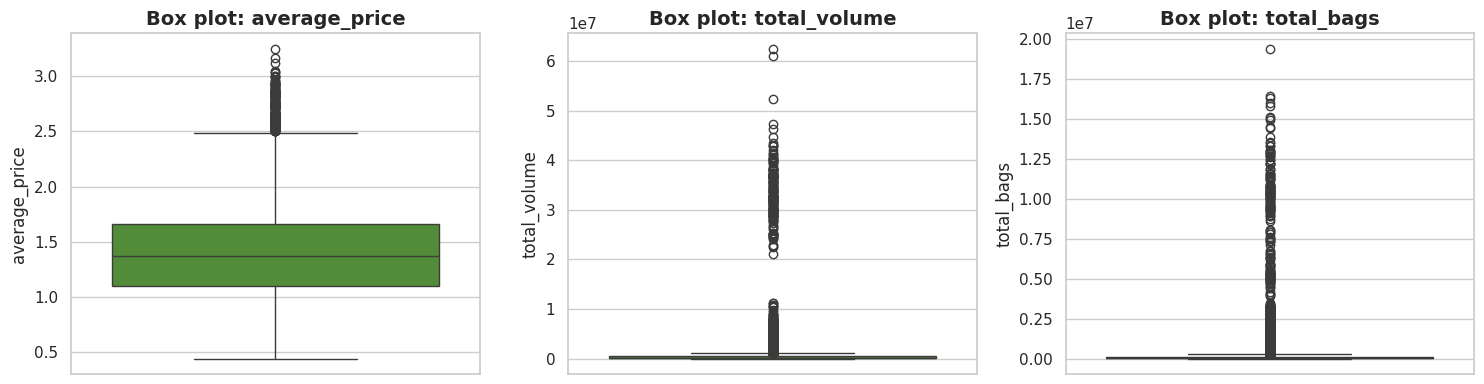

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["average_price", "total_volume", "total_bags"]):
    sns.boxplot(y=df[col], ax=ax, color="#4c9a2a")
    ax.set_title(f"Box plot: {col}")
plt.tight_layout()
plt.show()

### 4.6 Separate individual regions from aggregated regions
The `region` column mixes **cities**, **big regions** (West, Northeast...) and **TotalUS**. Comparing them directly would
be misleading (the totals would dominate volume), so a separate city-only dataframe is made for regional comparisons.

In [38]:
aggregate_regions = ["TotalUS", "California", "West", "Plains", "SouthCentral",
                     "Southeast", "Northeast", "Midsouth", "GreatLakes"]

df_cities = df[~df["region"].isin(aggregate_regions)].copy()
df_cities["region"] = df_cities["region"].cat.remove_unused_categories()

print("All rows      :", len(df))
print("City-only rows:", len(df_cities))
print("Cities        :", df_cities["region"].nunique())

All rows      : 18249
City-only rows: 15207
Cities        : 45


## 5. Exploratory Data Analysis (EDA)

In [39]:
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Years     :", sorted(df["year"].unique()))
print("Types     :", list(df["type"].unique()))
print("Regions   :", df["region"].nunique())

Date range: 2015-01-04 to 2018-03-25
Years     : [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Types     : ['conventional', 'organic']
Regions   : 54


In [40]:
df.groupby("type")[["average_price", "total_volume"]].agg(["mean", "median", "min", "max"]).round(2)

average_price                    total_volume             \
                      mean median   min   max         mean     median   
type                                                                    
conventional          1.16   1.13  0.46  2.22   1653212.90  408325.53   
organic               1.65   1.63  0.44  3.25     47811.21   10835.76   

                                     
                   min          max  
type                                 
conventional  33699.68  62505646.52  
organic          84.56   1814929.97

In [41]:
df.groupby("year")[["average_price", "total_volume"]].mean().round(2)

,average_price,total_volume
year,,
2015,1.38,781027.37
2016,1.34,858420.56
2017,1.52,862339.34
2018,1.35,1066927.73


## 6. Visualizations

### Visualization 1: Average Price Over Time (Line Chart)

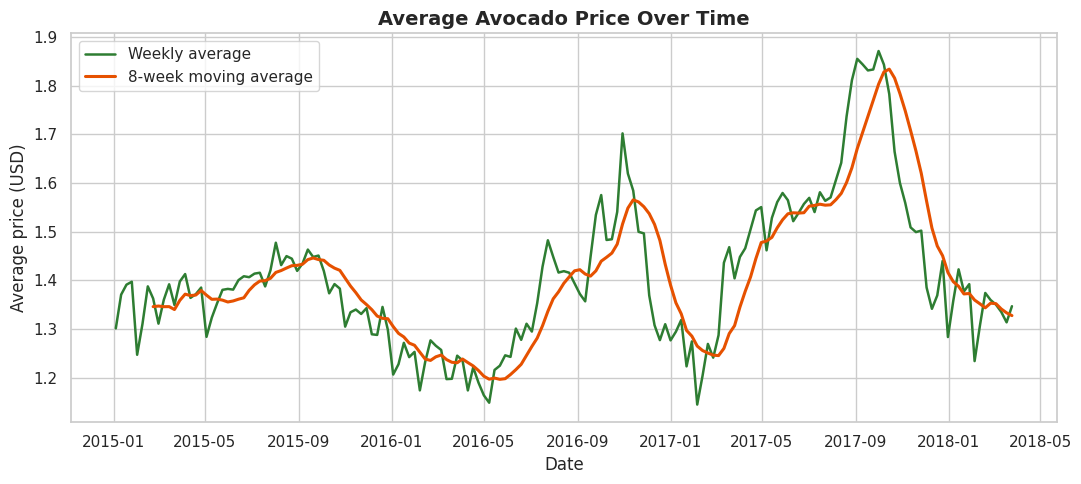

In [42]:
price_time = df.groupby("date")["average_price"].mean()

plt.figure()
plt.plot(price_time.index, price_time.values, color="#2e7d32", linewidth=1.8, label="Weekly average")
plt.plot(price_time.rolling(8).mean(), color="#e65100", linewidth=2.2, label="8-week moving average")
plt.title("Average Avocado Price Over Time")
plt.xlabel("Date")
plt.ylabel("Average price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

### Visualization 2: Organic vs Conventional Price (Bar Chart)

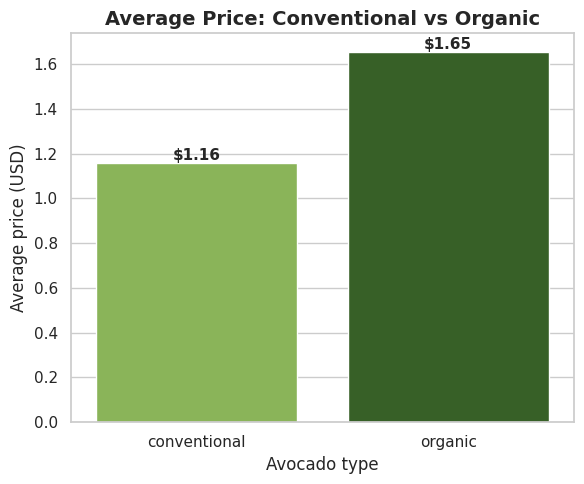

In [43]:
type_price = df.groupby("type")["average_price"].mean().sort_values()

plt.figure(figsize=(6, 5))
ax = sns.barplot(x=type_price.index.astype(str), y=type_price.values, palette=["#8bc34a", "#33691e"])
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.title("Average Price: Conventional vs Organic")
plt.xlabel("Avocado type")
plt.ylabel("Average price (USD)")
plt.tight_layout()
plt.show()

### Visualization 3: Average Price by Year (Bar Chart)

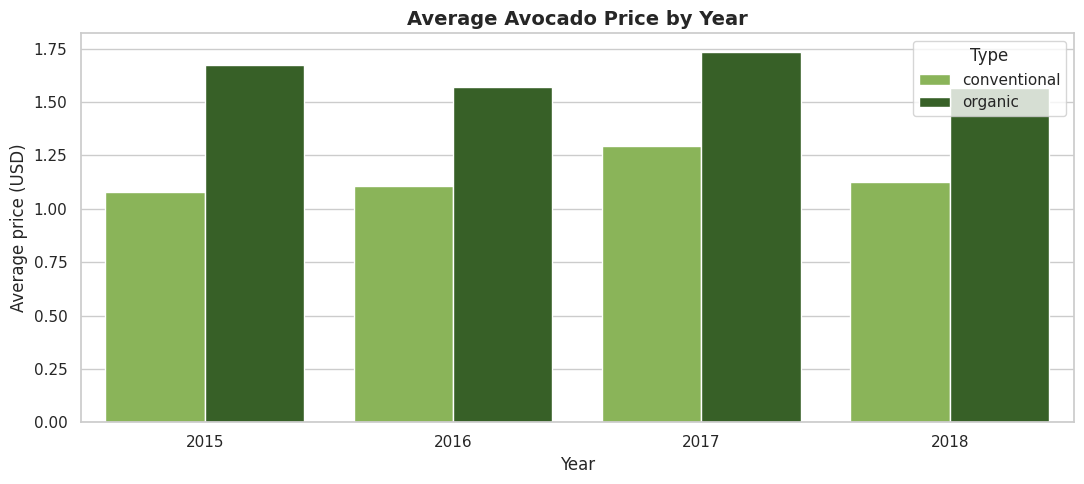

In [44]:
year_price = df.groupby(["year", "type"])["average_price"].mean().reset_index()

plt.figure()
ax = sns.barplot(data=year_price, x="year", y="average_price", hue="type", palette=["#8bc34a", "#33691e"])
plt.title("Average Avocado Price by Year")
plt.xlabel("Year")
plt.ylabel("Average price (USD)")
plt.legend(title="Type")
plt.tight_layout()
plt.show()

### Visualization 4: Average Price by Region (Bar Chart)

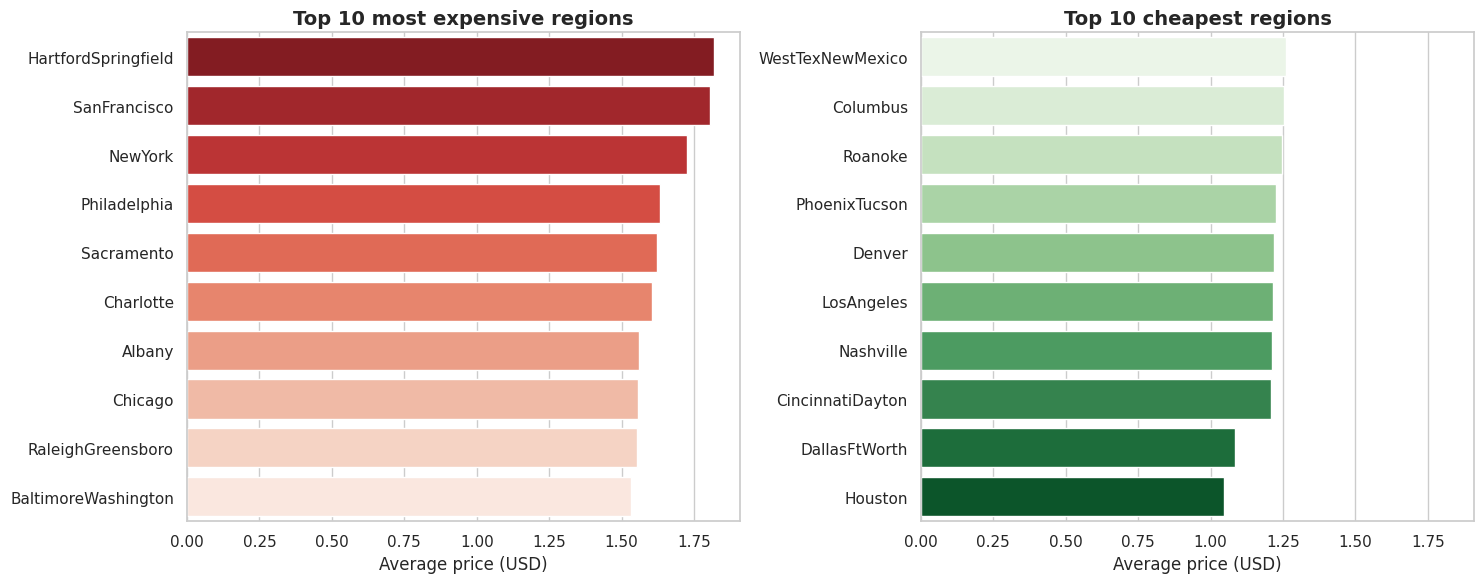

In [45]:
region_price = (df_cities.groupby("region")["average_price"].mean()
                .sort_values(ascending=False))

top, bottom = region_price.head(10), region_price.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
sns.barplot(x=top.values, y=top.index.astype(str), ax=axes[0], palette="Reds_r")
axes[0].set_title("Top 10 most expensive regions")
axes[0].set_xlabel("Average price (USD)")
axes[0].set_ylabel("")

sns.barplot(x=bottom.values, y=bottom.index.astype(str), ax=axes[1], palette="Greens")
axes[1].set_title("Top 10 cheapest regions")
axes[1].set_xlabel("Average price (USD)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### Visualization 5: Total Volume by Year (Line / Bar Chart)

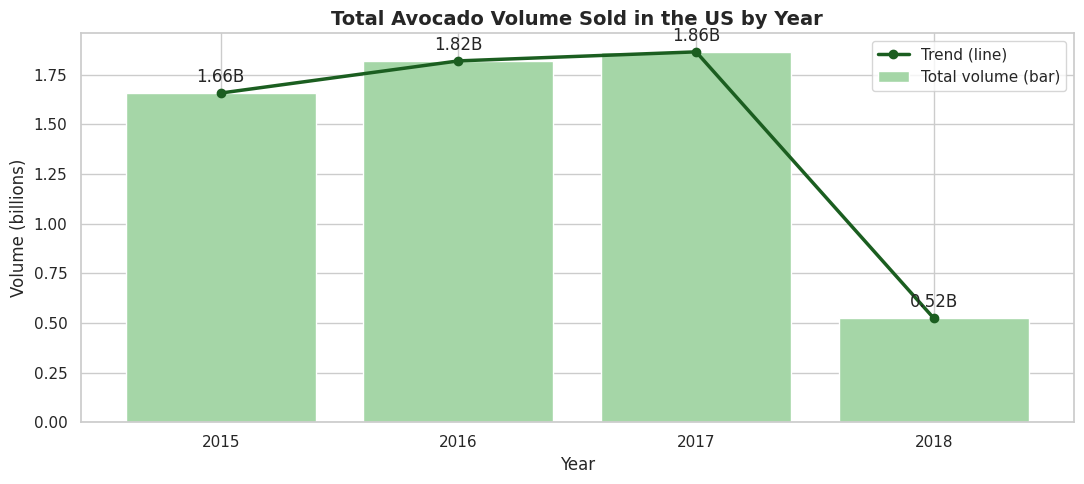

In [46]:
# TotalUS rows give the national weekly volume without double counting
us = df[df["region"] == "TotalUS"]
vol_year = us.groupby("year")["total_volume"].sum() / 1e9   # in billions of avocados

fig, ax = plt.subplots()
ax.bar(vol_year.index.astype(str), vol_year.values, color="#a5d6a7", label="Total volume (bar)")
ax.plot(vol_year.index.astype(str), vol_year.values, color="#1b5e20", marker="o", linewidth=2.5, label="Trend (line)")
for x, y in zip(vol_year.index.astype(str), vol_year.values):
    ax.annotate(f"{y:.2f}B", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Total Avocado Volume Sold in the US by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Volume (billions)")
ax.legend()
plt.tight_layout()
plt.show()

> **Note:** 2018 contains data only for the first ~3 months, so its total is lower because the year is incomplete, not because demand dropped.

### Visualization 6: Price vs Total Volume (Scatter Plot)

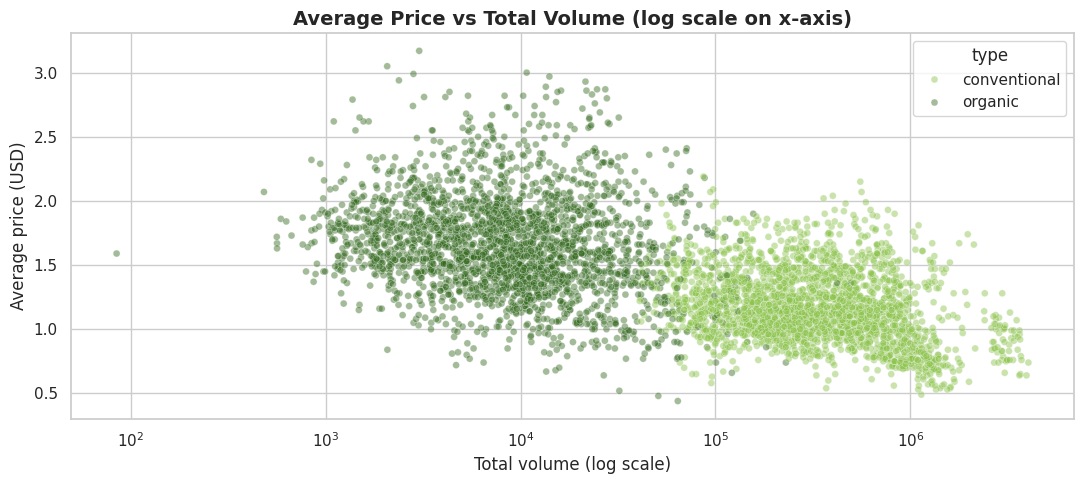

Correlation between price and log(volume): -0.616


In [47]:
sample = df_cities.sample(n=min(5000, len(df_cities)), random_state=42)

plt.figure()
sns.scatterplot(data=sample, x="total_volume", y="average_price", hue="type",
                alpha=0.45, palette=["#8bc34a", "#33691e"], s=25)
plt.xscale("log")
plt.title("Average Price vs Total Volume (log scale on x-axis)")
plt.xlabel("Total volume (log scale)")
plt.ylabel("Average price (USD)")
plt.tight_layout()
plt.show()

corr = np.corrcoef(np.log10(df_cities["total_volume"]), df_cities["average_price"])[0, 1]
print(f"Correlation between price and log(volume): {corr:.3f}")

## 7. Additional Plots

### 7.1 Distribution of Average Price

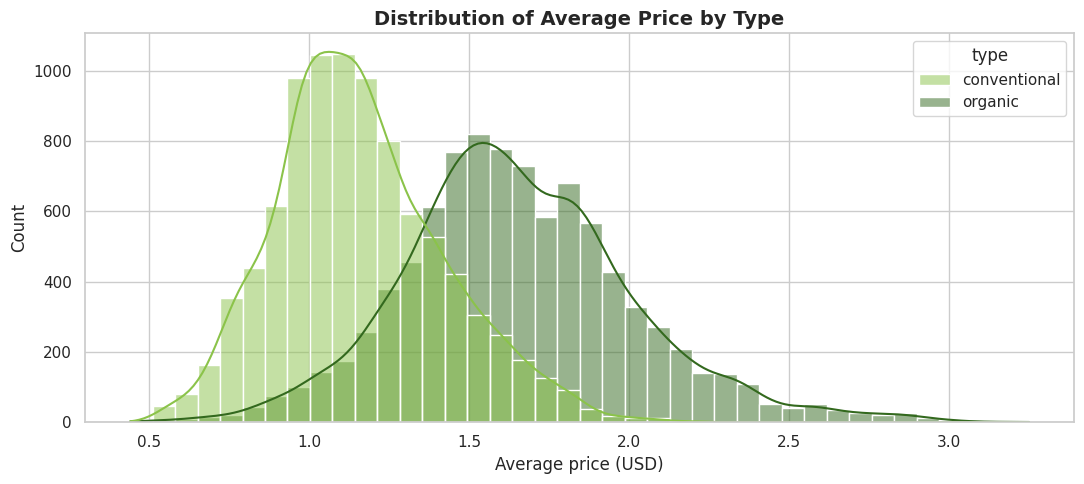

In [48]:
plt.figure()
sns.histplot(data=df, x="average_price", hue="type", kde=True, bins=40,
             palette=["#8bc34a", "#33691e"], alpha=0.5)
plt.title("Distribution of Average Price by Type")
plt.xlabel("Average price (USD)")
plt.tight_layout()
plt.show()

### 7.2 Price Spread by Type and Year (Box Plot)

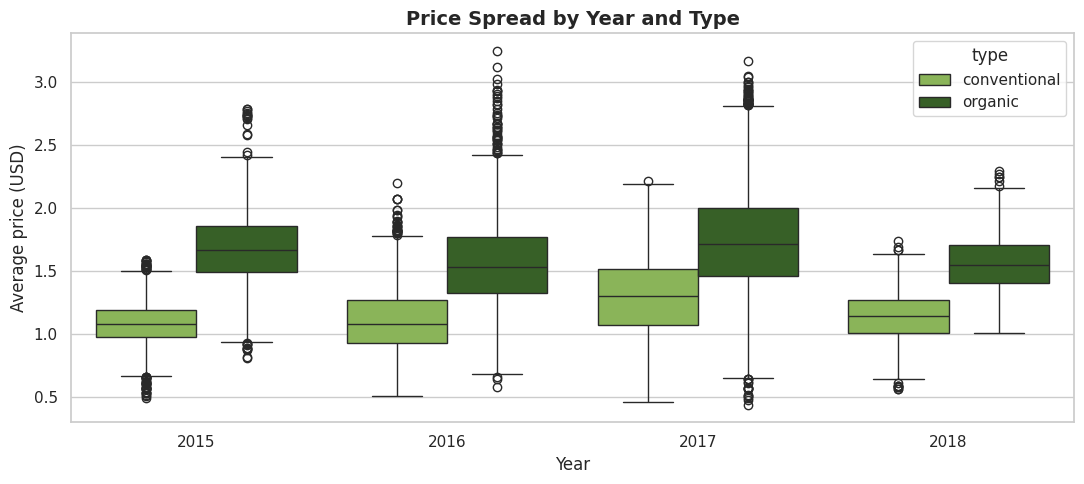

In [49]:
plt.figure()
sns.boxplot(data=df, x="year", y="average_price", hue="type", palette=["#8bc34a", "#33691e"])
plt.title("Price Spread by Year and Type")
plt.xlabel("Year")
plt.ylabel("Average price (USD)")
plt.tight_layout()
plt.show()

### 7.3 Seasonality: Average Price by Month

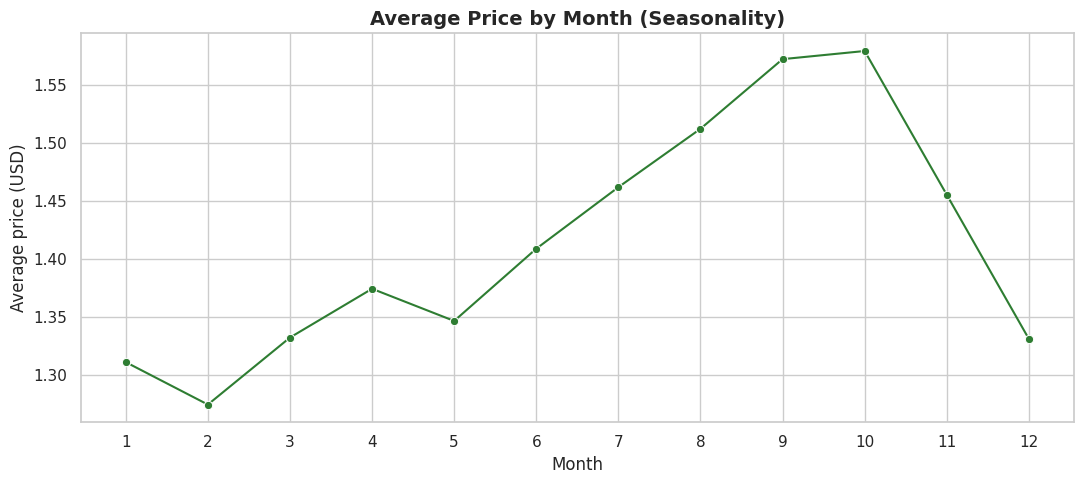

In [50]:
month_price = df.groupby("month")["average_price"].mean()

plt.figure()
sns.lineplot(x=month_price.index, y=month_price.values, marker="o", color="#2e7d32")
plt.xticks(range(1, 13))
plt.title("Average Price by Month (Seasonality)")
plt.xlabel("Month")
plt.ylabel("Average price (USD)")
plt.tight_layout()
plt.show()

### 7.4 Correlation Heatmap

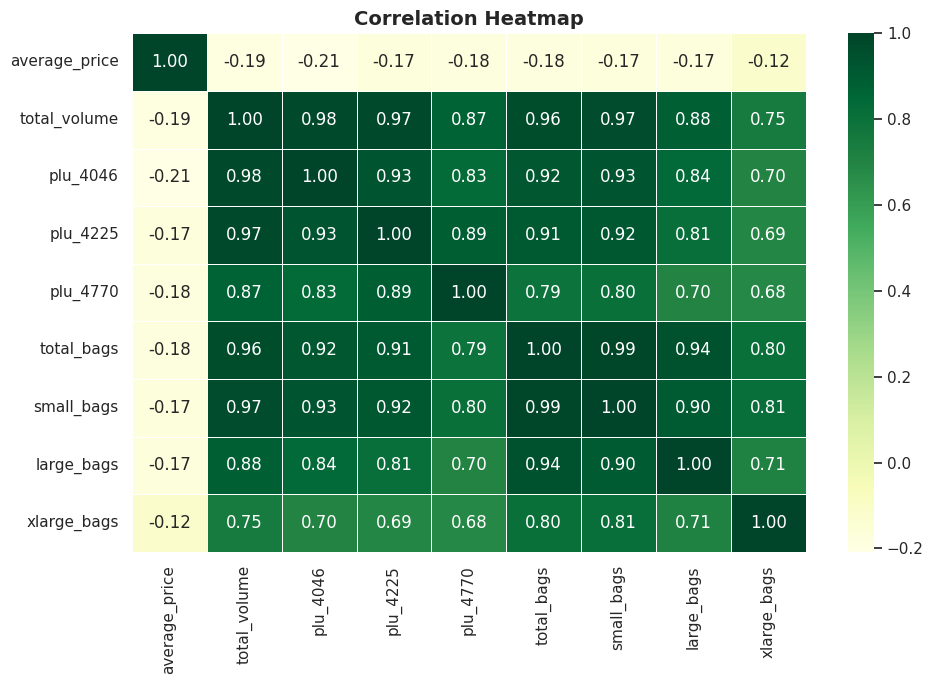

In [51]:
corr_cols = ["average_price", "total_volume", "plu_4046", "plu_4225", "plu_4770",
             "total_bags", "small_bags", "large_bags", "xlarge_bags"]

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="YlGn", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Insights Report

The numbers below are calculated directly from the data, so they stay correct for the dataset you load.

In [52]:
overall_avg = df["average_price"].mean()
t = df.groupby("type")["average_price"].mean()
y = df.groupby("year")["average_price"].mean()
r = df_cities.groupby("region")["average_price"].mean().sort_values()
m = df.groupby("month")["average_price"].mean()
us_vol = df[df["region"] == "TotalUS"].groupby("year")["total_volume"].sum()

print("=" * 60)
print("INSIGHTS REPORT: AVOCADO PRICE ANALYSIS")
print("=" * 60)
print(f"1. Dataset: {len(df):,} weekly records, {df['region'].nunique()} regions, "
      f"{df['date'].min().date()} to {df['date'].max().date()}.")
print(f"2. Overall average price: ${overall_avg:.2f} per avocado.")
print(f"3. Organic (${t['organic']:.2f}) is about {100*(t['organic']/t['conventional']-1):.0f}% "
      f"more expensive than conventional (${t['conventional']:.2f}).")
print(f"4. Highest-priced year: {y.idxmax()} (${y.max():.2f}); lowest-priced year: {y.idxmin()} (${y.min():.2f}).")
print(f"5. Most expensive region: {r.index[-1]} (${r.iloc[-1]:.2f}); cheapest region: {r.index[0]} (${r.iloc[0]:.2f}).")
print(f"6. Price is highest in month {m.idxmax()} (${m.max():.2f}) and lowest in month {m.idxmin()} (${m.min():.2f}).")
strength = "weak" if abs(corr) < 0.3 else "moderate" if abs(corr) < 0.6 else "strong"
direction = "negative (higher volume tends to go with lower prices)" if corr < 0 else "positive (higher volume tends to go with higher prices)"
print(f"7. Correlation between price and log(volume): {corr:.2f} -> a {strength}, {direction} relationship.")
full_years = us_vol.drop(index=us_vol.index.max())   # last year is incomplete
print(f"8. Full-year US volume went from {full_years.iloc[0]/1e9:.2f}B ({full_years.index[0]}) "
      f"to {full_years.iloc[-1]/1e9:.2f}B ({full_years.index[-1]}).")
print(f"9. Outliers were detected in price and volume but kept, as they reflect real market events.")

INSIGHTS REPORT: AVOCADO PRICE ANALYSIS
1. Dataset: 18,249 weekly records, 54 regions, 2015-01-04 to 2018-03-25.
2. Overall average price: $1.41 per avocado.
3. Organic ($1.65) is about 43% more expensive than conventional ($1.16).
4. Highest-priced year: 2017 ($1.52); lowest-priced year: 2016 ($1.34).
5. Most expensive region: HartfordSpringfield ($1.82); cheapest region: Houston ($1.05).
6. Price is highest in month 10 ($1.58) and lowest in month 2 ($1.27).
7. Correlation between price and log(volume): -0.62 -> a strong, negative (higher volume tends to go with lower prices) relationship.
8. Full-year US volume went from 1.66B (2015) to 1.86B (2017).
9. Outliers were detected in price and volume but kept, as they reflect real market events.


## 9. Conclusion
This project covered the full data analysis workflow in Python: **data cleaning** (types, missing values, duplicates,
outliers), **exploratory analysis**, **six main visualizations plus four extra plots**, and a data-driven **insights report**.

The insights report above summarises the main findings: the organic vs conventional price gap, how prices changed by year,
region and season, and how sales volume relates to price.

**Libraries used:** Python, Pandas, NumPy, Matplotlib, Seaborn | **Environment:** Jupyter Notebook / Google Colab